Hücre 1: Kütüphanelerin Yüklenmesi ve İçe Aktarılması

In [ ]:
# Hücre 1: Kütüphanelerin İçe Aktarılması ve Dizin Yapılandırması
import os
import json
import requests
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

# Proje kök dizinini dinamik olarak tespit et (hem notebook hem kök dizin çalıştırmalarını destekler)
cwd = Path.cwd()
PROJECT_ROOT = cwd if (cwd / "data").exists() else cwd.parent
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "countries.json"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "countries_processed.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Ortam değişkenlerini .env dosyasından yükle
load_dotenv(PROJECT_ROOT / ".env")
load_dotenv()

# Görselleştirme stil ayarları
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
sns.set_theme(style="whitegrid")
print(f"Proje dizini başarıyla tanımlandı: {PROJECT_ROOT}")

Proje dizini başarıyla tanımlandı: c:\Users\elmas\OneDrive\Masaüstü\data_project


Hücre 2: Verinin API'den Çekilmesi

In [2]:
# Hücre 2: Verinin API'den Çekilmesi ve Yedek (Fallback) Mekanizması
api_token = os.getenv("REST_COUNTRIES_API_TOKEN")
url = "https://api.restcountries.com/countries/v5"
headers = {"Authorization": f"Bearer {api_token}"} if api_token else {}

countries_data = None

print("API'den güncel veriler çekilmeye çalışılıyor...")
try:
    if not api_token:
        raise ValueError("REST_COUNTRIES_API_TOKEN bulunamadı (.env dosyası eksik veya boş).")

    # Sayfalanarak (Pagination) API'den tüm ülkeleri çekelim
    all_countries = []
    limit = 100
    offset = 0

    while True:
        params = {"limit": limit, "offset": offset}
        response = requests.get(url, headers=headers, params=params, timeout=20)
        response.raise_for_status()
        res_json = response.json()

        # Gelen yanıtı incele ve objects listesini ayıkla
        objects = []
        has_more = False

        if isinstance(res_json, dict) and "data" in res_json:
            data_sec = res_json["data"]
            if isinstance(data_sec, dict):
                objects = data_sec.get("objects", [])
                meta = data_sec.get("meta", {})
                has_more = meta.get("more", False)
            elif isinstance(data_sec, list):
                objects = data_sec
        elif isinstance(res_json, list):
            objects = res_json
        else:
            raise ValueError(f"API beklenmeyen format döndürdü: {res_json}")

        # Liste kontrolü
        if not isinstance(objects, list):
            raise ValueError("API yanıtından ülke listesi ayıklanamadı!")

        all_countries.extend(objects)
        if not has_more or not objects:
            break
        offset += len(objects)

    if not isinstance(all_countries, list) or len(all_countries) == 0:
        raise ValueError("API'den geçerli ülke listesi alınamadı!")

    countries_data = all_countries
    print(f"API'den toplam {len(countries_data)} ülkenin ham verisi başarıyla çekildi!")

    # Yalnızca geçerli liste olduğunda yerel ham JSON'a kaydet
    RAW_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    with open(RAW_DATA_PATH, "w", encoding="utf-8") as f:
        json.dump({"success": True, "data": {"objects": countries_data}, "errors": []}, f, ensure_ascii=False, indent=2)

except Exception as e:
    # Fallback mekanizması: API hatasında veya çevrimdışıyken yerel dosyadan oku
    print(f"[UYARI] API isteği başarısız oldu: {e}")
    print(f"Fallback devrede: '{RAW_DATA_PATH}' yerel dosyasından okunuyor...")

    if RAW_DATA_PATH.exists():
        with open(RAW_DATA_PATH, "r", encoding="utf-8") as f:
            local_json = json.load(f)

        if isinstance(local_json, dict) and isinstance(local_json.get("data"), dict):
            countries_data = local_json["data"].get("objects", [])
        elif isinstance(local_json, list):
            countries_data = local_json
        elif isinstance(local_json, dict) and "objects" in local_json:
            countries_data = local_json.get("objects", [])

    # Eğer ham JSON boş veya geçersizse işlenmiş CSV'den oku
    if not isinstance(countries_data, list) or len(countries_data) == 0:
        if PROCESSED_DATA_PATH.exists():
            print(f"[BİLGİ] Ham JSON bulunamadı veya boş. İşlenmiş CSV'den okunuyor: '{PROCESSED_DATA_PATH}'")
            cached_df = pd.read_csv(PROCESSED_DATA_PATH)
            countries_data = cached_df.to_dict(orient="records")
        else:
            raise FileNotFoundError(f"Ne API ne de yerel veri dosyaları ({RAW_DATA_PATH}) bulunamadı!")

    print(f"[BAŞARILI] Toplam {len(countries_data)} ülkenin verisi başarıyla yüklendi!")

# Sonraki analiz adımları için veri normalizasyonu (v5 API ve yerel şema uyumu)
for c in countries_data:
    if isinstance(c, dict):
        if "name" not in c and "names" in c:
            c["name"] = c["names"]
        elif "Country" in c and "name" not in c:
            c["name"] = c["Country"]
        if isinstance(c.get("area"), dict):
            c["area"] = c["area"].get("kilometers")
        elif "Area" in c and "area" not in c:
            c["area"] = c["Area"]
        if "Population" in c and "population" not in c:
            c["population"] = c["Population"]
        if "Region" in c and "region" not in c:
            c["region"] = c["Region"]
        if isinstance(c.get("languages"), list):
            c["languages"] = {
                l.get("name"): l.get("name")
                for l in c["languages"]
                if isinstance(l, dict) and "name" in l
            }
        elif "Languages" in c and "languages" not in c:
            c["languages"] = c["Languages"]


API'den güncel veriler çekilmeye çalışılıyor...
API'den toplam 254 ülkenin ham verisi başarıyla çekildi!


Hücre 3: Verinin DataFrame'e Dönüştürülmesi ve Temizlenmesi

In [3]:
# Hücre 3: Verinin DataFrame'e Dönüştürülmesi ve Temizlenmesi
df = pd.DataFrame(countries_data)

# Ülke adını iç içe yapıdan (name.common) veya düz metinden güvenle çıkaralım
if "name" in df.columns:
    df["name"] = df["name"].apply(
        lambda x: x.get("common") if isinstance(x, dict) else (str(x) if pd.notna(x) else None)
    )
elif "names" in df.columns:
    df["name"] = df["names"].apply(
        lambda x: x.get("common") if isinstance(x, dict) else (str(x) if pd.notna(x) else None)
    )
else:
    print("Uyarı: 'name' sütunu bulunamadı!")

print("İlk durum (Satır, Sütun):", df.shape)

# Sayısal alanları dönüştür
if "population" in df.columns:
    df["population"] = pd.to_numeric(df["population"], errors="coerce")
if "area" in df.columns:
    df["area"] = pd.to_numeric(df["area"], errors="coerce")

# Temizlik Adımları:
# 1. Eksik değer kontrolü (Nüfus, alan veya bölgesi boş olan kayıtları eleyelim)
required_cols = ["name", "population", "area", "region"]
cols_to_check = [col for col in required_cols if col in df.columns]
df = df.dropna(subset=cols_to_check)

# 2. Tekrar eden kayıt kontrolü
if "name" in df.columns:
    dup_count = df.duplicated(subset=["name"]).sum()
    print(f"Tekrar eden ülke kaydı sayısı: {dup_count}")
    if dup_count > 0:
        df = df.drop_duplicates(subset=["name"])

# 3. Nüfus yoğunluğu (Population Density) sütununu hesaplayalım (Kişi / km²)
if "population" in df.columns and "area" in df.columns:
    df["population_density"] = df["population"] / df["area"].replace(0, pd.NA)

# Temizlenmiş veriyi data/processed klasörüne kaydedelim
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_DATA_PATH, index=False, encoding="utf-8")

print(f"Temizlenmiş veri kaydedildi: {PROCESSED_DATA_PATH}")
print("Güncel veri boyutu:", df.shape)
df[["name", "population", "area", "region", "population_density"]].head()

İlk durum (Satır, Sütun): (254, 35)
Tekrar eden ülke kaydı sayısı: 0
Temizlenmiş veri kaydedildi: c:\Users\elmas\OneDrive\Masaüstü\data_project\data\processed\countries_processed.csv
Güncel veri boyutu: (254, 36)


,name,population,area,region,population_density
0,Abkhazia,244236,8665.0,Asia,28.186497
1,Afghanistan,43844000,652230.0,Asia,67.221686
2,Albania,2335930,28748.0,Europe,81.255392
3,Algeria,47400000,2381741.0,Africa,19.901408
4,American Samoa,43268,199.0,Oceania,217.427136


### Soru 1: Kıtasal Dil Dağılımı
Hangi kıtada hangi diller en yaygın olarak konuşuluyor ve kaçar ülkede resmi/yaygın olarak yer alıyor?

Grafik kaydedildi: c:\Users\elmas\OneDrive\Masaüstü\data_project\reports\figures\continent_languages_bar.png


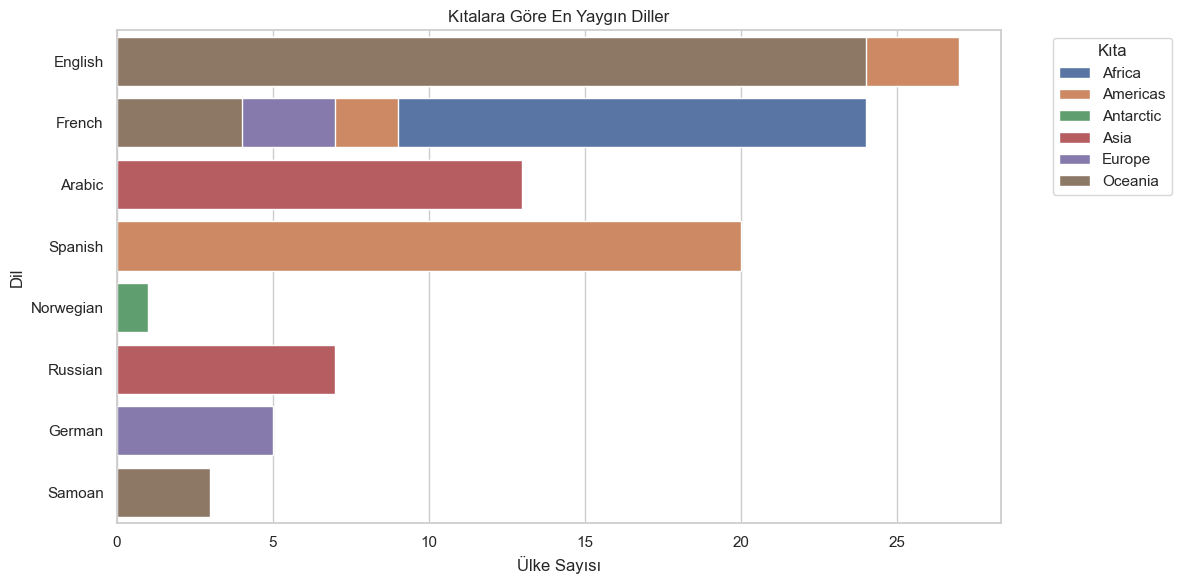

In [4]:
# Soru 1: Kıtasal Dil Dağılımı
lang_region_list = []

for index, row in df.iterrows():
    region = row.get("region")
    languages = row.get("languages")
    if not region:
        continue
    if isinstance(languages, dict):
        for lang_code, lang_name in languages.items():
            lang_region_list.append({"region": region, "language": lang_name})
    elif isinstance(languages, list):
        for item in languages:
            lang_name = item.get("name") if isinstance(item, dict) else str(item)
            lang_region_list.append({"region": region, "language": lang_name})
    elif isinstance(languages, str):
        for lang_name in languages.split(","):
            if lang_name.strip():
                lang_region_list.append({"region": region, "language": lang_name.strip()})

lang_df = pd.DataFrame(lang_region_list)

if not lang_df.empty:
    # Her kıtada en çok konuşulan ilk 3 dili bulalım
    top_langs = lang_df.groupby(["region", "language"]).size().reset_index(name="count")
    top_langs = top_langs.sort_values(["region", "count"], ascending=[True, False])
    top_3_per_region = top_langs.groupby("region").head(3)

    # Görselleştirme (Bar Chart)
    plt.figure(figsize=(12, 6))
    sns.barplot(data=top_3_per_region, x="count", y="language", hue="region", dodge=False)
    plt.title("Kıtalara Göre En Yaygın Diller")
    plt.xlabel("Ülke Sayısı")
    plt.ylabel("Dil")
    plt.legend(title="Kıta", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

    fig_file = FIGURES_DIR / "continent_languages_bar.png"
    plt.savefig(fig_file)
    print(f"Grafik kaydedildi: {fig_file}")
    plt.show()
else:
    print("Dil verisi bulunamadı.")

### Soru 2: Nüfus Yoğunluğu (Population Density)
Ülkelerin nüfus ve yüzölçümü ilişkisine göre nüfus yoğunlukları (kişi/km²) nasıl dağılıyor?

Grafik kaydedildi: c:\Users\elmas\OneDrive\Masaüstü\data_project\reports\figures\population_density_hist.png


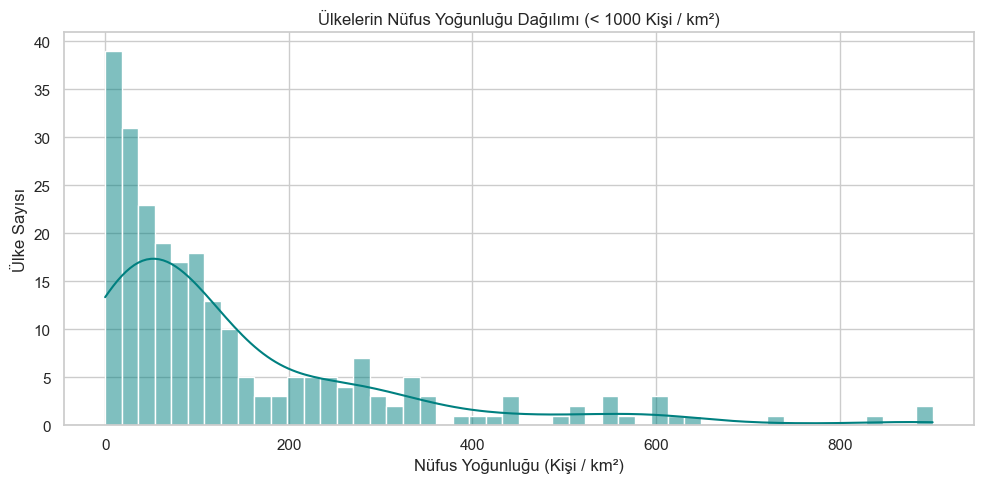


--- En Yoğun Nüfuslu 5 Ülke ---
     name  population_density
    Macau        22883.333333
   Monaco        19236.138614
Singapore         8744.366197
Hong Kong         6791.757246
Gibraltar         6366.000000

--- En Seyrek Nüfuslu 5 Ülke ---
                             name  population_density
                    Bouvet Island            0.000000
Heard Island and McDonald Islands            0.000000
                       Antarctica            0.000093
                    South Georgia            0.007686
                        Greenland            0.026289


In [5]:
# Soru 2: Nüfus Yoğunluğu (Population Density)
plt.figure(figsize=(10, 5))
valid_density = df["population_density"].dropna()

# Aşırı uç değerleri (outlier) histogramda daha net görmek için 1000'den küçükleri filtreleyelim
sns.histplot(valid_density[valid_density < 1000], bins=50, kde=True, color="teal")
plt.title("Ülkelerin Nüfus Yoğunluğu Dağılımı (< 1000 Kişi / km²)")
plt.xlabel("Nüfus Yoğunluğu (Kişi / km²)")
plt.ylabel("Ülke Sayısı")
plt.tight_layout()

fig_file = FIGURES_DIR / "population_density_hist.png"
plt.savefig(fig_file)
print(f"Grafik kaydedildi: {fig_file}")
plt.show()

# En yoğun ve en seyrek nüfuslu ilk 5 ülke
print("\n--- En Yoğun Nüfuslu 5 Ülke ---")
print(df.nlargest(5, "population_density")[["name", "population_density"]].to_string(index=False))

print("\n--- En Seyrek Nüfuslu 5 Ülke ---")
print(df.nsmallest(5, "population_density")[["name", "population_density"]].to_string(index=False))

### Soru 3: Alan-Nüfus İlişkisi (Area-Population Correlation)
Bir ülkenin yüzölçümünün büyüklüğü ile nüfusu arasında doğrudan istatistiksel bir ilişki (korelasyon) var mı?

Grafik kaydedildi: c:\Users\elmas\OneDrive\Masaüstü\data_project\reports\figures\area_vs_population_scatter.png


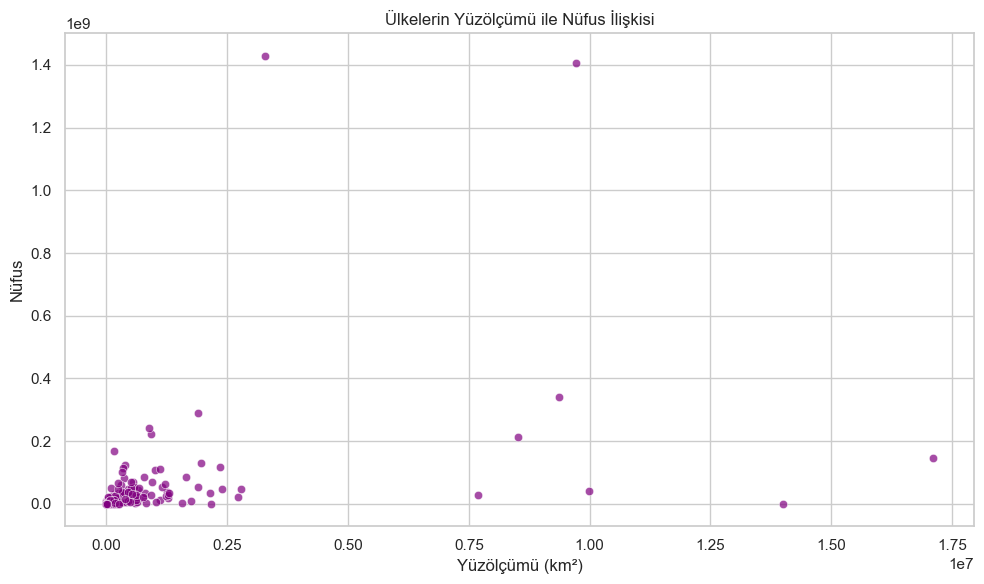

Yüzölçümü ile Nüfus arasındaki Pearson Korelasyonu: 0.4024


In [6]:
# Soru 3: Alan-Nüfus İlişkisi (Area-Population Correlation)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="area", y="population", alpha=0.7, color="purple")
plt.title("Ülkelerin Yüzölçümü ile Nüfus İlişkisi")
plt.xlabel("Yüzölçümü (km²)")
plt.ylabel("Nüfus")
plt.tight_layout()

fig_file = FIGURES_DIR / "area_vs_population_scatter.png"
plt.savefig(fig_file)
print(f"Grafik kaydedildi: {fig_file}")
plt.show()

# Korelasyon katsayısı hesaplama
corr = df[["area", "population"]].corr().loc["area", "population"]
print(f"Yüzölçümü ile Nüfus arasındaki Pearson Korelasyonu: {corr:.4f}")